# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
df=pd.read_csv('data/comptage-velos.csv', sep=';')
print(df.info())

print()

print(df['date'].dtype)

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.6 KB
None

str


Ce n'est pas satisfaisant car on préfère un type 'datetime' pour traiter les données.

In [3]:
print(df['date'].is_monotonic_increasing)

False


Non, le fichier n'est pas trié par date.

In [4]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [5]:
brut=df.copy()
brut['date']=pd.to_datetime(brut['date'], format='%Y-%m-%d')
brut=brut.set_index('date')
brut=brut['comptage']
brut=brut.sort_index()

In [6]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [7]:
double=brut[(brut.index).duplicated()]
print(len(double), double.index)

print()

print( (brut.isna()).sum() , brut[brut.isna()].index )

print()

print( brut.describe() )
print( brut[brut==0].index)
print(brut[brut>(3*brut.median())].index)

3 DatetimeIndex(['2023-05-25', '2023-12-21', '2024-02-27'], dtype='datetime64[us]', name='date', freq=None)

8 DatetimeIndex(['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09',
               '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'],
              dtype='datetime64[us]', name='date', freq=None)

count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
Name: comptage, dtype: float64
DatetimeIndex(['2024-06-27'], dtype='datetime64[us]', name='date', freq=None)
DatetimeIndex(['2024-07-04'], dtype='datetime64[us]', name='date', freq=None)


- Trois dates apparaissent en double : les 25/05/2023, 21/12/2023 et 27/02/2024 (en dd-mm-aaaa)
- Huit valeurs manquent : les 23/02/2023, 25/06/2023, 01/12/2023, 09/01/2024, 08/02/2024, 13/03/2024, 17/11/2024 et 22/11/2024
- Le minimum de 0 paraît peut probable pour une ville où la moyenne de vélo passant est 2500 et où le compte ne descend quasi jamais sous les 1000, même en période hivernale...
  Le maximum peut être possible s'il y avait une course ce jour-là... D'autant que la valeur est unique
- Le compteur atteint une fois 0 : le 27/06/2024
- Le compteur dépasse trois fois la médiane une fois : le 04/07/2024

In [8]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [9]:
velos=brut[~( (brut.index).duplicated() )].copy()
velos.loc['2024-06-27'], velos.loc['2024-07-04'] = np.nan, np.nan
velos=velos.interpolate()

(not velos.index.duplicated().any()) & (len(velos)==731) & (velos.isna().sum()==0)

np.True_

In [10]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [11]:
hebdo=velos.resample('W').mean()
mensuel=velos.resample('ME').mean()
annuel=velos.resample('YE').sum()

print(len(hebdo), len(mensuel))

106 24


hebdo n'a pas exactement 731/7 lignes car les semaines se terminent nécessairement le dimanche (donc cela rajoute des 'semaines' si on ne commence pas un lundi et qu'on ne finit pas un dimanche)

In [12]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

In [13]:
lisse=velos.rolling(7, center=True).mean()
print(lisse.isna().sum())

6


- Il y a 6 NaN : 3 au début et 3 à la fin car il n'y a pas assez de data "autour" pour calculer une moyenne centrée
- 7 jours est un bon choix car cela correspond à une tendance hebdomadaire qui efface les variations au sein d'une semaine qui sont dûes au rythme des gens (moins de déplacements le dimanche par exemple)

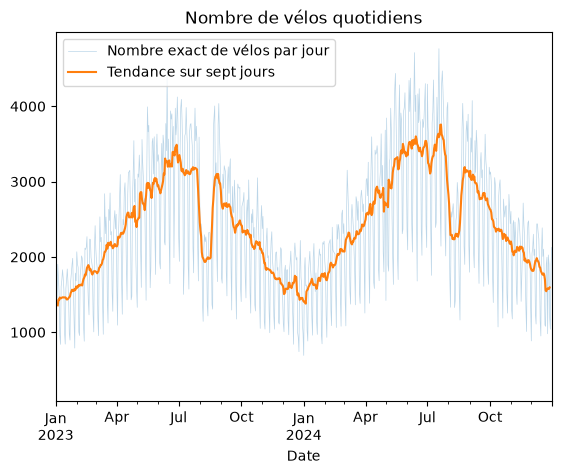

In [14]:
velos.plot(alpha=0.3, lw=0.5, label="Nombre exact de vélos par jour")
lisse.plot(label="Tendance sur sept jours")
plt.title("Nombre de vélos quotidiens")
plt.xlabel("Date")
plt.legend()
plt.show()

In [15]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [16]:
profil_semaine=velos.groupby(velos.index.dayofweek).mean()
profil_semaine.index=["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

moy_semaine=profil_semaine[["lun", "mar", "mer", "jeu", "ven"]].mean()
print(((moy_semaine - profil_semaine["dim"]) / moy_semaine) *100, '%.')

49.83395691464415 %.


In [17]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [18]:
profil_mois=velos.groupby(velos.index.month).mean()
print(profil_mois.idxmax())

6


- Le mois le plus chargé est juin
- En août, le nombre diminue car les Parisiens partent en vacances !

In [19]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [20]:
_2023, _2024 = velos.resample('YE').mean().iloc[0], velos.resample('YE').mean().iloc[1]
croissance=((_2024-_2023)/_2023)*100
print(croissance, '%')

par_mois=velos.groupby([velos.index.month, velos.index.year]).mean()
par_mois=par_mois.unstack()

par_mois_bis=velos.groupby([velos.index.year, velos.index.month]).mean()
print(par_mois_bis.pct_change().idxmax())

10.481613797717293 %
(np.int32(2024), np.int32(4))


La croissance à été maximum entre le mois de mars 2024 et le mois de d'avril 2024.

In [21]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

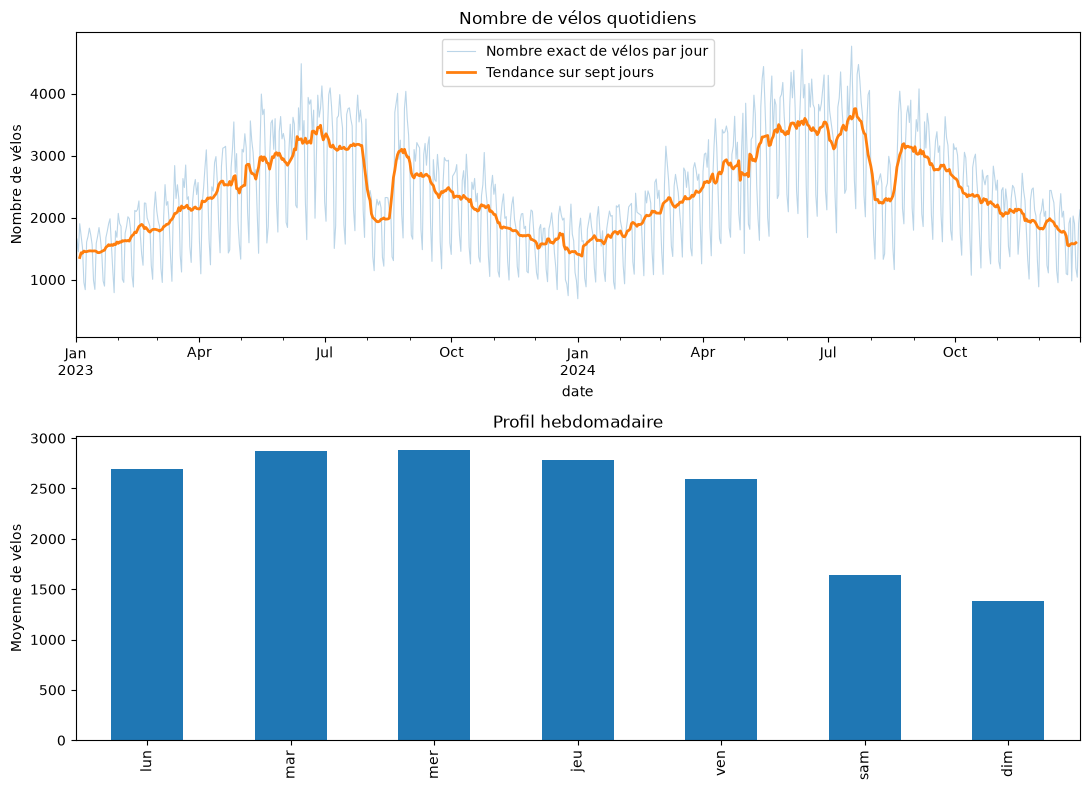

In [22]:
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))

velos.plot(ax=ax_haut, alpha=0.3, lw=0.8, label="Nombre exact de vélos par jour")
lisse.plot(ax=ax_haut, lw=2, label="Tendance sur sept jours")
ax_haut.set_title("Nombre de vélos quotidiens")
ax_haut.set_ylabel("Nombre de vélos")
ax_haut.legend()

profil_semaine.plot(ax=ax_bas, kind="bar")
ax_bas.set_title("Profil hebdomadaire")
ax_bas.set_ylabel("Moyenne de vélos")

fig.tight_layout()
fig.savefig("serie.png")
plt.show()

In [23]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

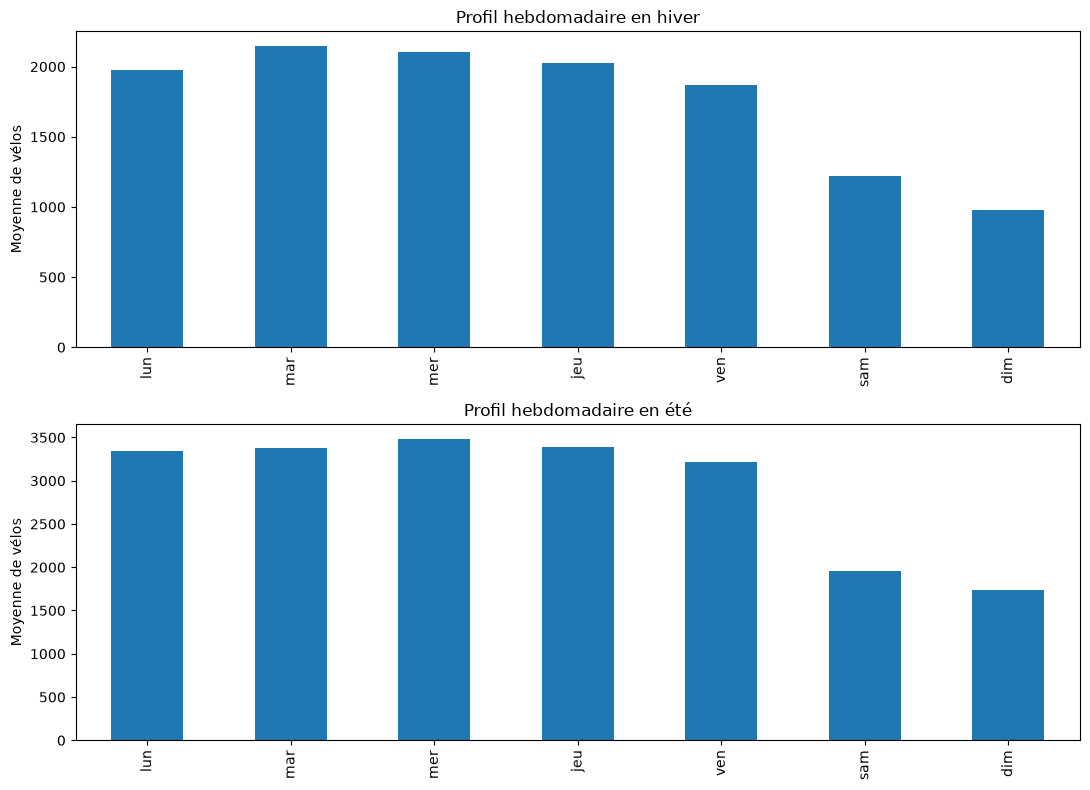

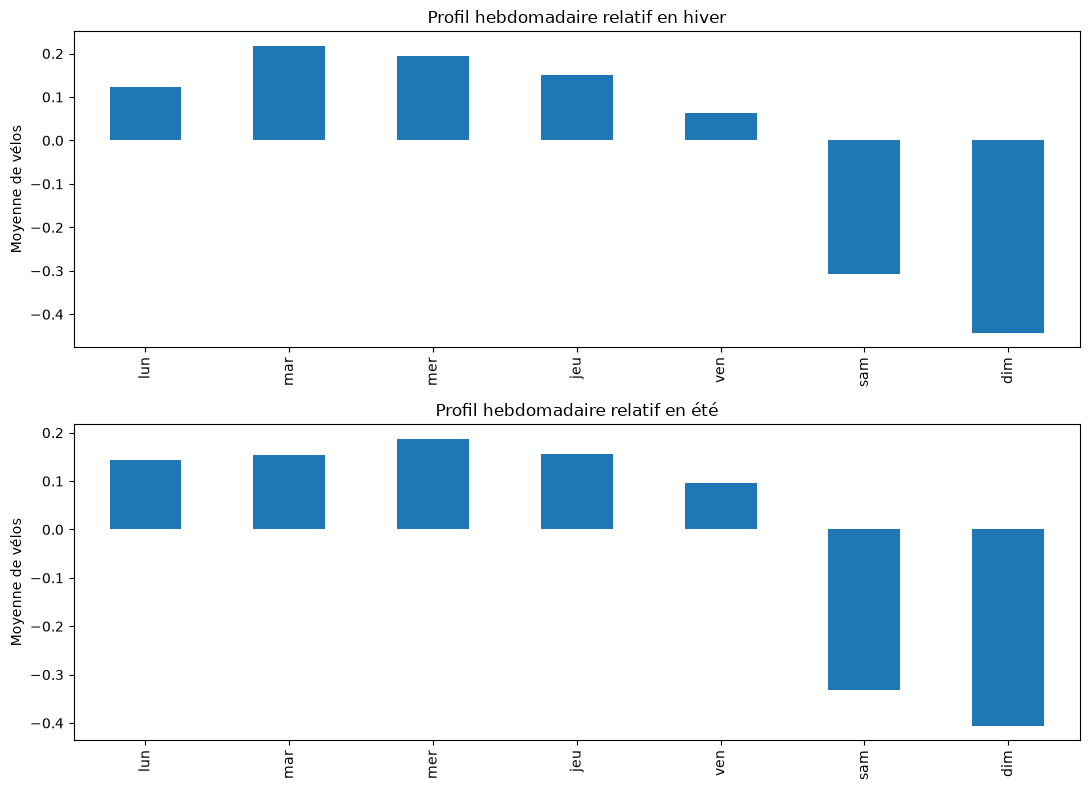

In [24]:
##Question 2 : L’écart week-end / semaine est-il le même en été et en hiver ?


#1er graphique : Profils hebdomadaires absolus en été et hiver
fig1, (ax_haut1, ax_bas1) = plt.subplots(2, 1, figsize=(11, 8))

hiver=velos[((velos.index>='2023-12-21')&(velos.index<'2024-03-21'))|(velos.index<'2023-03-21')|(velos.index>='2024-12-21')]
profil_semaine_hiver=hiver.groupby(hiver.index.dayofweek).mean()
profil_semaine_hiver.index=["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]


ete=velos[((velos.index>='2023-06-21')&(velos.index<'2023-09-21'))|((velos.index>='2024-06-21')&(velos.index<'2024-09-21'))]
profil_semaine_ete=ete.groupby(ete.index.dayofweek).mean()
profil_semaine_ete.index=["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]


profil_semaine_hiver.plot(ax=ax_haut1, kind="bar")
ax_haut1.set_title("Profil hebdomadaire en hiver")
ax_haut1.set_ylabel("Moyenne de vélos")

profil_semaine_ete.plot(ax=ax_bas1, kind="bar")
ax_bas1.set_title("Profil hebdomadaire en été")
ax_bas1.set_ylabel("Moyenne de vélos")

fig1.tight_layout()
fig1.savefig("Profils_absolus.png")
plt.show()

#2eme graphique : Profils hebdomadaires relatifs en été et hiver
fig2, (ax_haut2, ax_bas2) = plt.subplots(2, 1, figsize=(11, 8))

profil_relatif_hiver=(profil_semaine_hiver-profil_semaine_hiver.mean())/profil_semaine_hiver.mean()
profil_relatif_ete=(profil_semaine_ete-profil_semaine_ete.mean())/profil_semaine_ete.mean()

profil_relatif_hiver.plot(ax=ax_haut2, kind="bar")
ax_haut2.set_title("Profil hebdomadaire relatif en hiver")
ax_haut2.set_ylabel("Moyenne de vélos")

profil_relatif_ete.plot(ax=ax_bas2, kind="bar")
ax_bas2.set_title("Profil hebdomadaire relatif en été")
ax_bas2.set_ylabel("Moyenne de vélos")

fig2.tight_layout()
fig2.savefig("Profils_relatifs.png")
plt.show()

- En hiver : les utilisateurs prennent 31% moins le vélo le samedi que sur le reste de la semaine
             les utilisateurs prennent 44% moins le vélo le dimanche que sur le reste de la semaine
- En été :   les utilisateurs prennent 33% moins le vélo le samedi que sur le reste de la semaine
             les utilisateurs prennent 41% moins le vélo le dimanche que sur le reste de la semaine

Donc, en réalité, l'écart we-semaine est sensiblement le même en hiver et en été 

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [25]:
#Bo.1

print('Le moins chargé :', velos.idxmin(), velos.idxmin().day_name())
print('Le plus chargé :', velos.idxmax(), velos.idxmax().day_name())


Le moins chargé : 2023-01-01 00:00:00 Sunday
Le plus chargé : 2024-07-18 00:00:00 Thursday


Explication : 
- le 1er janvier est un jour férié, qui plus est un dimanche, d'où les faibles déplacements 
- le 18 juillet correspond à la période estivale, plus propice au vélo

In [26]:
#Bo.2

annuel=velos.resample('YE').sum()
print( ( (annuel.iloc[1]-annuel.iloc[0]) / annuel.iloc[0] ) *100 ,'%')

10.78430315058774 %


Les résultats sont légèrement différents car 2024 était une année bissextile ! 
Donc, quand on calcule d'abord la moyenne par année et qu'ensuite on fait la moyenne des moyennes (concept du 3c), on "efface" le fait que 2024 soit bissextile, c'est plus significatif.
Ici, comme on travaille avec des sommes, il y a un terme de plus dans l'année 2024 et donc le total de 2024 est encore plus important par rapport à 2023, d'où la croissance plus élevée (10,78 contre 10,48 pour la 3c).

Bon courage à tous ! Pour toute question sur le sujet, écrivez-moi à [aurelien.noce@minesparis.psl.eu](mailto:aurelien.noce@minesparis.psl.eu), en mettant [aurelien.noce@imagine-app.fr](mailto:aurelien.noce@imagine-app.fr) en copie : la messagerie de l'école perd parfois des mails, la seconde adresse sert de filet.

Au plaisir de vous lire,

votre responsable de cours, Aurélien Noce